In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
from src.session_loader import Session

2024-12-04 12:05:10.622762: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-12-04 12:05:10.622802: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-12-04 12:05:10.622808: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
reg_matrix = np.load(r'processed-data/Oct_2021/registration/5592_accepted_only_registered_ids.npy')
indexing = np.load(r'processed-data/Oct_2021/registration/5592_accepted_only_session_indexing.npy', allow_pickle=True).item()
print(reg_matrix.shape, indexing)

(1355, 10) {'HBTD6': 0, 'HBTD5': 1, 'Pool': 2, 'HBTD2': 3, 'Empty': 4, 'HBTD4': 5, 'Stranger': 6, 'HBTD1': 7, 'Toy': 8, 'HBTD3': 9}


In [9]:
session_file = pd.read_csv('data/log/SESSION_FILE_event_associated_cells_definition_2024-10-08_11-44-29.csv')
session_file.head()

,Excluded,Session,Cohort,Date,Mouse,Pair,Criteria,Sex,Final Outcome,Session Outcome,...,AdaNotes,Comments,Num of liberation cells,% of liberation cells,% of randomd liberation cells,Num of randomd liberation cells,Num of random event cells,% of random event cells,Normalized random event components,Liberation Associated Cells Metadata Path
0,False,RECNvlCtx,Jan_2024,22.01.2024,8000,8000-7999,SSCW,M,H,H,...,NaN,NaN,12.0,12.631579,NaN,NaN,12.0,12.631579,8.450310,processed-data/event_associated_cells_definiti...
1,True,Hab1,Jan_2024,NaN,8000,8000-7999,NaN,M,H,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,processed-data/event_associated_cells_definiti...
2,False,HBTD6,Jan_2024,20.01.2024,8000,8000-7999,SSCW,M,H,H,...,NaN,NaN,4.0,12.903226,NaN,NaN,4.0,12.903226,3.068485,processed-data/event_associated_cells_definiti...
3,False,HBTD5,Jan_2024,19.01.2024,8000,8000-7999,SSCW,M,H,H,...,NaN,NaN,5.0,14.285714,NaN,NaN,5.0,14.285714,5.028344,processed-data/event_associated_cells_definiti...
4,False,Pool,Jan_2024,24.01.2024,8000,8000-7999,SSCW,M,H,CTRL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,processed-data/event_associated_cells_definiti...


In [10]:
session_file = session_file[session_file['Mouse'] == 5592]
session_file.head()

,Excluded,Session,Cohort,Date,Mouse,Pair,Criteria,Sex,Final Outcome,Session Outcome,...,AdaNotes,Comments,Num of liberation cells,% of liberation cells,% of randomd liberation cells,Num of randomd liberation cells,Num of random event cells,% of random event cells,Normalized random event components,Liberation Associated Cells Metadata Path
105,False,HBTD6,Oct_2021,29.10.2021,5592,5592-5757,SSCW,F,H,H,...,0.1,(ADA NOTE: 0.1 min),38.0,20.765027,NaN,NaN,38.0,20.765027,18.600331,processed-data/event_associated_cells_definiti...
106,False,HBTD5,Oct_2021,28.10.2021,5592,5592-5757,SSCW,F,H,H,...,0.1,(ADA NOTE: 0.1 min),42.0,20.192308,NaN,NaN,42.0,20.192308,16.358743,processed-data/event_associated_cells_definiti...
107,False,Pool,Oct_2021,31.10.2021,5592,5592-5757,SSCW,F,NaN,CTRL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,processed-data/event_associated_cells_definiti...
108,False,HBTD2,Oct_2021,24.10.2021,5592,5592-5757,SSCW,F,H,H,...,1.5,(ADA NOTE: 1.5),35.0,11.363636,NaN,NaN,35.0,11.363636,10.401273,processed-data/event_associated_cells_definiti...
109,False,Empty,Oct_2021,30.10.2021,5592,5592-5757,SSCW,F,NaN,CTRL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,processed-data/event_associated_cells_definiti...


In [11]:
pos_dic = {}

for i, row in session_file.iterrows():
    session = Session(row)
    positions = session.extract_neuron_positions(session.get_neuron_labels())
    pos_dic[session.session] = positions

pos_dic

{'HBTD6': array([[ 27., 159.],
        [ 13., 262.],
        [ 32., 303.],
        [  8., 332.],
        [ 36., 386.],
        [ 18., 399.],
        [ 12., 415.],
        [ 26., 414.],
        [ 49., 190.],
        [ 53., 232.],
        [ 73., 256.],
        [ 62., 317.],
        [ 52., 351.],
        [ 52., 335.],
        [ 67., 342.],
        [ 56., 381.],
        [ 51., 377.],
        [ 74., 375.],
        [ 56., 439.],
        [ 48., 440.],
        [ 74., 459.],
        [ 75., 448.],
        [ 50., 459.],
        [106., 185.],
        [114., 195.],
        [105., 250.],
        [121., 310.],
        [104., 304.],
        [ nan,  nan],
        [122., 332.],
        [101., 328.],
        [101., 354.],
        [113., 332.],
        [104., 341.],
        [118., 349.],
        [119., 389.],
        [ 93., 385.],
        [ 97., 428.],
        [105., 440.],
        [102., 470.],
        [106., 449.],
        [ 91., 478.],
        [122., 461.],
        [115., 456.],
        [112., 488.],
 

In [12]:
import numpy as np
from collections import defaultdict
from scipy.spatial.distance import pdist
from typing import Dict, List, Tuple
import pandas as pd

def compute_distances(assignments: np.ndarray, 
                       indexing: Dict[str, int], 
                       positions: Dict[str, np.ndarray]) -> Tuple[np.ndarray, np.ndarray]:
    """
    Compute distances between registered and non-registered neurons.

    Parameters
    ----------
    assignments : np.ndarray
        Array of assigned neuron IDs across sessions.
    indexing : Dict[str, int]
        Dictionary mapping session keys to column indices in assignments.
    positions : Dict[str, np.ndarray]
        Dictionary mapping session keys to arrays of neuron positions.

    Returns
    -------
    Tuple[np.ndarray, np.ndarray]
        Two numpy arrays containing equal number of pairwise distances: 
        registered_distances and non_registered_distances.
    """
    registered_distances: List[float] = []
    non_registered_distances: List[float] = []

    # Calculate distances for registered neurons
    for i in range(assignments.shape[0]):
        neuron_positions = [positions[k][int(assignments[i, j]), :] for k, j in indexing.items() if not np.isnan(assignments[i, j])]
        if len(neuron_positions) > 1:
            dists = pdist(neuron_positions)
            registered_distances.extend(dists)

    # Calculate distances for all neurons within each session
    for s in positions.values():
        dists = pdist(s)
        non_registered_distances.extend(dists)

    # Ensure both lists have the same number of samples
    min_length = min(len(registered_distances), len(non_registered_distances))
    return np.array(registered_distances[:min_length]), np.array(non_registered_distances[:min_length])

In [13]:
reg_dist, non_reg_dist = compute_distances(reg_matrix, indexing, pos_dic)
print(reg_dist.shape, non_reg_dist.shape)

(5993,) (5993,)


<Axes: title={'center': 'Distance between Neurons'}, ylabel='Y-axis Label'>

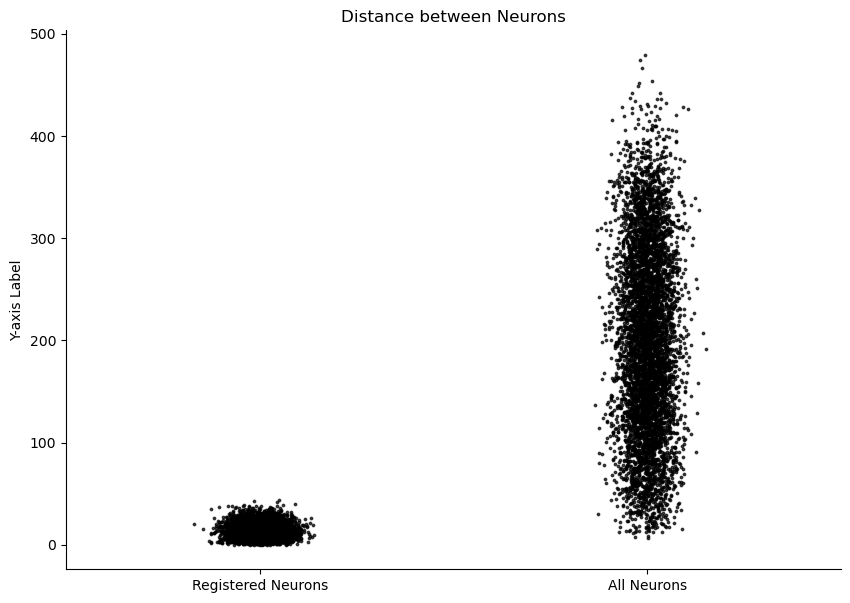

In [15]:
fig, ax = plt.subplots(figsize=(10, 7))
from src.plotting import plot_boxplots

plot_boxplots(reg_dist, non_reg_dist, ax, labels=('Registered Neurons', 'All Neurons'), title='Distance between Neurons')

In [19]:
from src.registration_utils import *

stats = calculate_registration_stats(reg_matrix)
stats

# Add Animal and Cohort columns
stats['Animal'] = 5592
stats['Cohort'] = 'Synthetic'
stats

,Percentage,K,Animal,Cohort
0,100.00,1,5592,Synthetic
1,67.08,2,5592,Synthetic
2,46.35,3,5592,Synthetic
3,33.28,4,5592,Synthetic
4,20.52,5,5592,Synthetic
5,11.07,6,5592,Synthetic
6,4.72,7,5592,Synthetic
7,1.62,8,5592,Synthetic
8,0.44,9,5592,Synthetic
9,0.22,10,5592,Synthetic


/home/aagafono/projects/helping-behaviour-calcium-imaging/src/plotting.py:38: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


<Axes: title={'center': '% of Registered Components vs. Number of Sessions\nCohort Oct_2021'}, xlabel='Number of Sessions (K)', ylabel='Percentage (%)'>

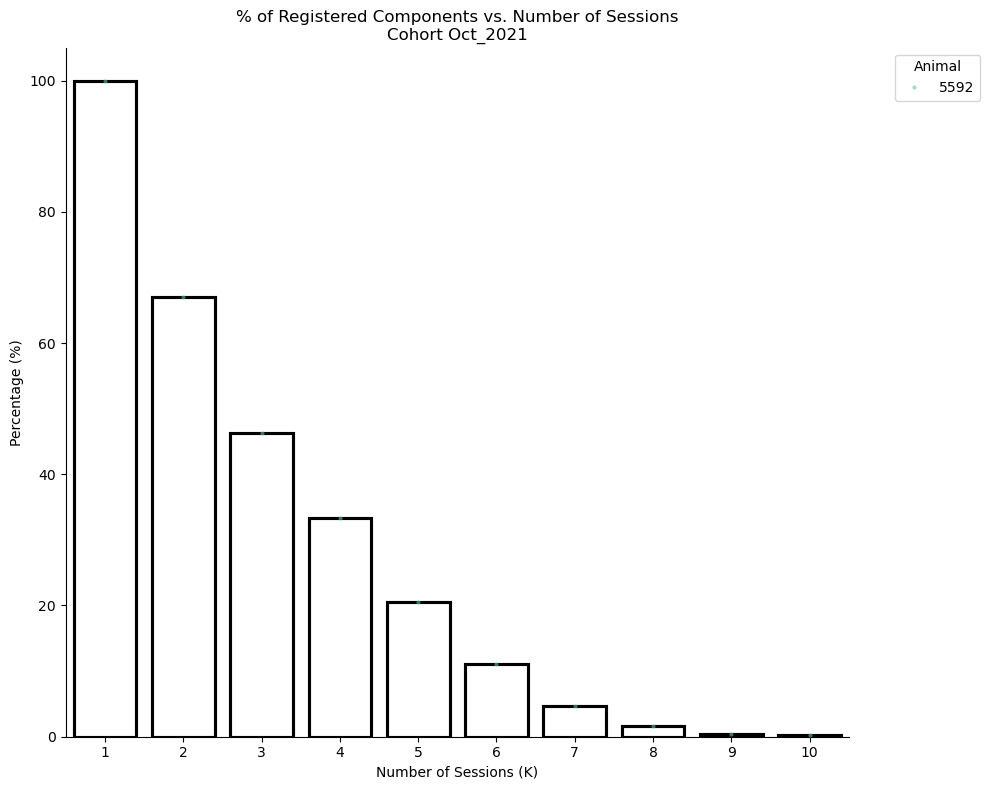

In [22]:
from src.plotting import plot_registration_validation

plot_registration_validation(stats, 'Oct_2021', output_path=None, ax=None)